# Impeachment Discourse: Topic Modeling + Rule-Based Sentiment (Single Notebook)

**Topic:** Impeachment trial of VP Sara Duterte  
**Covers Main_obj.md:** 200+ records · LDA topic modeling (3+ topics, k-search, coherence/perplexity) · rule-based sentiment (pos/neu/neg) · 90/10 holdout + 10-fold CV · scripts/outputs/remarks table (Section E).

**Why this file exists:** the full app (`app.py` + 8 `modules/`) is powerful but heavy (Streamlit, torch/transformers, gensim). This notebook does the *graded* pipeline only, with 5 libraries (`pandas, scikit-learn, nltk, vaderSentiment, matplotlib`), sklearn-LDA only, no GPU, no server. Same results logic, ~300 lines, runs top-to-bottom.

| Step | Main_obj | Notebook section |
|---|---|---|
| Collection | ≥200 records, varied topics | §1 Load |
| Preprocessing | analytics process | §2 Clean |
| Topic modeling | LDA, ≥3 topics, evaluate + discuss | §4–5 |
| Sentiment | rule-based 3-class | §6 |
| Validation | 90/10 + 10-fold + metrics | §7 |
| Report | scripts/outputs/remarks | §8 table |

> Stance ≠ tone: `political_bloc` = side (Pro-Duterte / Pro-Accountability / Undecided); sentiment = wording tone. An angry defense of Sara = Negative tone, Pro-Duterte stance.

In [1]:
# §0 — Setup: 5 libraries only. Run once: pip install pandas scikit-learn nltk vaderSentiment matplotlib
import os, re
from hashlib import sha1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split

# NLTK english stopwords (offline-safe fallback if download blocked)
try:
    from nltk.corpus import stopwords as _nltk_sw
    try:
        EN_SW = set(_nltk_sw.words('english'))
    except LookupError:
        import nltk; nltk.download('stopwords'); EN_SW = set(_nltk_sw.words('english'))
except Exception:
    EN_SW = {'the','a','an','and','or','of','to','in','on','is','are','was','were','it','this','that'}
print('imports ok · sklearn LDA backend (no gensim needed)')

# ---- tunables (the ONLY numbers you might defend changing) ----
RANDOM_STATE = 42
HOLDOUT_FRAC = 0.10   # Main_obj: 10% unseen
CV_FOLDS = 10         # Main_obj: 10-fold (auto-reduced if a class is tiny, see §7)
POS_THRESH, NEG_THRESH = 0.15, -0.15
MIN_TOKENS = 3
K_MIN, K_MAX = 3, 6   # narrow search: faster + more interpretable than 2..10

# Words that must NEVER be deleted (flip/intensify meaning)
PROTECTED = {'hindi','huwag','wag','wala','walang','not','no','never','ni','di','ayaw',
             'sobra','sobrang','masyado','grabe','napaka','very','super','talaga'}


imports ok · sklearn LDA backend (no gensim needed)


## §1 Load data (target: 200+ records)

**Script:** read `data/raw_data.csv` → map `comment_text→text`, normalize platform, stable content-hash ids, drop exact duplicates, left-join hand labels from `data/gold_labels.csv` (if present). webscraped rows start *unlabeled* — unsupervised steps use all rows, validation uses labeled rows only.

In [2]:
def stable_id(t):
    norm = re.sub(r'\s+', ' ', str(t or '').strip().lower())
    return sha1(norm.encode('utf-8', errors='ignore')).hexdigest()[:12]

def norm_platform(s):
    k = str(s or '').lower()
    if 'face' in k: return 'Facebook'
    if 'youtu' in k: return 'YouTube'
    if 'twitter' in k or k.strip() in ('x',): return 'X'
    return str(s) if s else 'Other'

raw = pd.read_csv('data/raw_data.csv')
text_col = next(c for c in raw.columns if c.lower() in ('comment_text','text','comment','content','message','body'))
df = pd.DataFrame({
    'text': raw[text_col].astype(str),
    'platform': (raw['platform'] if 'platform' in raw.columns else raw.get('source', 'Other')).apply(norm_platform),
    'source': raw['post_url'] if 'post_url' in raw.columns else raw.get('source', 'raw_data.csv'),
})
df = df[df['text'].str.strip().ne('')].copy()
df['__k'] = df['text'].str.strip().str.lower()
df = df.drop_duplicates(subset=['__k']).drop(columns=['__k']).reset_index(drop=True)
df['id'] = df['text'].apply(stable_id)
df['manual_sentiment'] = ''
df['political_bloc'] = 'Undecided/Neutral'
if os.path.exists('data/gold_labels.csv'):
    gold = pd.read_csv('data/gold_labels.csv').drop_duplicates(subset=['id'])
    df = df.merge(gold, on='id', how='left', suffixes=('', '_g'))
    for c in ('manual_sentiment', 'political_bloc'):
        if c + '_g' in df.columns:
            df[c] = df[c + '_g'].fillna(df[c]); df = df.drop(columns=[c + '_g'])
    df['manual_sentiment'] = df['manual_sentiment'].fillna('')

n_lab = int(df['manual_sentiment'].isin(['Positive','Negative','Neutral']).sum())
print(f'rows={len(df)} (target 200+: {"PASS" if len(df) >= 200 else "FAIL"}) · labeled={n_lab}')
print(df['platform'].value_counts())
print(df['manual_sentiment'].value_counts(dropna=False).head())
df.head(3)

rows=2742 (target 200+: PASS) · labeled=39
platform
Facebook    1643
YouTube      899
X            200
Name: count, dtype: int64
manual_sentiment
            2703
Negative      25
Positive       9
Neutral        5
Name: count, dtype: int64


,text,platform,source,id,manual_sentiment,political_bloc
0,Senate archives Sara Duterte impeachment case ...,X,https://x.com/ABSCBNNews/status/19530857392118...,972f8af59e32,,Undecided/Neutral
1,@ABSCBNNews Lord kunin mo na po un 19,X,https://x.com/ABSCBNNews/status/19530857392118...,6b48f856bdc8,,Undecided/Neutral
2,@ABSCBNNews Kaway kaway sa galit na galit sa I...,X,https://x.com/ABSCBNNews/status/19530857392118...,e030ee597366,,Undecided/Neutral


## §2 Preprocess (one simple pass)

**Script:** lowercase → strip URLs → strip @mentions → keep hashtag words (`#DueProcess→dueprocess`) → collapse repeats (`grabeee→grabe`) → slang map (`data/taglish_slang.csv`, ~30 rows) → tokenize → remove stopwords (NLTK-EN + `data/stopwords_tl.txt`, PROTECTED kept) → drop rows with `< MIN_TOKENS` tokens.

**Output:** `clean_text` + `tokens`. **Remark:** retention + top words tell you if cleaning worked (top words should be content words, not `ang/ng/sa/the`).

kept 2366/2742 (86%) · dropped empties + <3-token rows
                                                                                                                                                                                                                                   text                                                                                                                                               clean_text
0                                                                                                                                                                 Senate archives Sara Duterte impeachment case https://t.co/FdWJyVgm2z                                                                                                            senate archives sara duterte impeachment case
1                                                                                                                                                                              

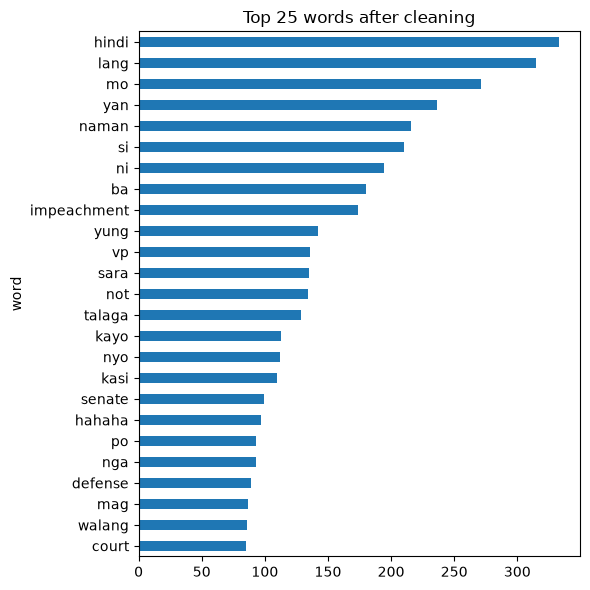

In [3]:
# slang map (tiny csv: variant,canonical)
SLANG = {}
if os.path.exists('data/taglish_slang.csv'):
    for line in open('data/taglish_slang.csv', encoding='utf-8').read().splitlines()[1:]:
        if ',' in line:
            k, v = [x.strip().lower() for x in line.split(',', 1)]
            if k and v: SLANG[k] = v

# tagalog stopwords: vendored file if present, else small builtin
TL_SW = set()
if os.path.exists('data/stopwords_tl.txt'):
    TL_SW = {l.strip().lower() for l in open('data/stopwords_tl.txt', encoding='utf-8')
               if l.strip() and not l.startswith('#')}
else:
    TL_SW = {'ang','ng','sa','mga','na','ay','at','ako','ikaw','siya','kami','kayo','sila','ito','iyan','iyon','yung','yang','nang'}
STOP = ((EN_SW | TL_SW) - PROTECTED)

def clean_text(t):
    t = str(t or '').lower()
    t = re.sub(r'http\S+', ' ', t)          # urls
    t = re.sub(r'@\w+', ' ', t)            # mentions
    t = t.replace('#', '')                 # keep hashtag WORD
    t = re.sub(r'(.)\1{2,}', r'\1\1', t)  # grabeee -> grabe
    t = re.sub(r'[^a-z\s]', ' ', t)        # keep letters only (simple)
    toks = [SLANG.get(w, w) for w in t.split()]
    return [w for w in toks if w and w not in STOP]

df['tokens'] = df['text'].apply(clean_text)
df['clean_text'] = df['tokens'].apply(' '.join)
df['n_tokens'] = df['tokens'].apply(len)
before = len(df)
df = df[df['n_tokens'] >= MIN_TOKENS].reset_index(drop=True)
print(f'kept {len(df)}/{before} ({len(df)/before:.0%}) · dropped empties + <{MIN_TOKENS}-token rows')
print(df[['text','clean_text']].head(3).to_string())

# word frequencies (for remarks)
from collections import Counter
freq = Counter(w for ts in df['tokens'] for w in ts)
freq_df = pd.DataFrame(freq.most_common(25), columns=['word','count'])
print(freq_df.to_string(index=False))
freq_df.plot.barh(x='word', y='count', legend=False, figsize=(6,6), title='Top 25 words after cleaning'); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## §3 (Optional, 1 chart) Do platforms talk differently?

Not required by Main_obj — skip on a tight deadline. One TF-IDF cosine matrix between platforms, for one discussion sentence.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
try:
    groups = df.groupby('platform')['clean_text'].apply(lambda s: ' '.join(s)).to_dict()
    names = list(groups)
    M = TfidfVectorizer(max_features=2000).fit_transform([groups[g] for g in names])
    cos = pd.DataFrame(cosine_similarity(M), index=names, columns=names).round(3)
    print('TF-IDF cosine between platforms (1=identical):')
    print(cos)
except Exception as e:
    print('similarity skipped:', e)

TF-IDF cosine between platforms (1=identical):
          Facebook      X  YouTube
Facebook     1.000  0.626    0.716
X            0.626  1.000    0.556
YouTube      0.716  0.556    1.000


## §4 Topic modeling — LDA k-search (Main_obj: ≥3 topics + metrics)

**Script:** `CountVectorizer` → sklearn `LDA` for each k in 3..6 → record **perplexity** (lower = better fit) + **mean-NPMI coherence** over top-10 words (higher = words co-occur in real comments = human-interpretable). Pick best-k by coherence.

**Why sklearn only:** gensim has no Python-3.14 wheel; sklearn-LDA runs everywhere with identical interpretation (each doc = mix of topics, each topic = mix of words).

k=3: coherence=0.0666 perplexity=1002.0
k=4: coherence=0.0972 perplexity=1075.3
k=5: coherence=0.0824 perplexity=1113.8
k=6: coherence=0.1214 perplexity=1159.5
 k  coherence_npmi  perplexity
 3          0.0666      1002.0
 4          0.0972      1075.3
 5          0.0824      1113.8
 6          0.1214      1159.5

BEST k = 6 (highest coherence)


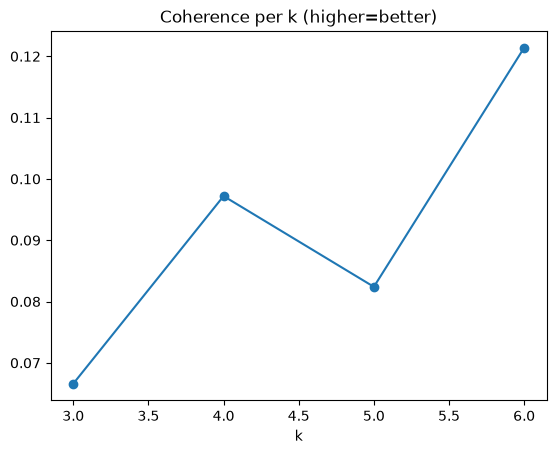

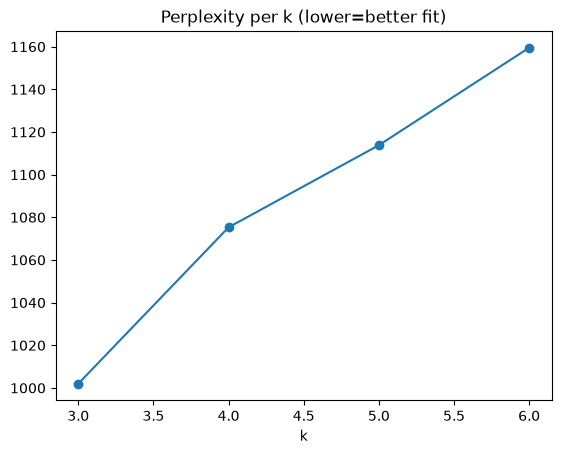

In [5]:
def mean_npmi(top_words, binary, vocab):
    """Mean NPMI over word pairs in one topic (simple, transparent coherence)."""
    idx = [vocab.get(w, -1) for w in top_words]
    idx = [i for i in idx if i >= 0]
    if len(idx) < 2: return 0.0
    B = (binary[:, idx].toarray() > 0) if hasattr(binary, 'toarray') else (np.asarray(binary)[:, idx] > 0)
    n = B.shape[0]
    p = np.asarray(B.mean(axis=0)).ravel() + 1e-12
    vals = []
    for a in range(len(idx)):
        for b in range(a+1, len(idx)):
            pij = float((B[:, a] & B[:, b]).mean()) + 1e-12
            pmi = np.log(pij / (p[a]*p[b]))
            vals.append(pmi / (-np.log(pij)))
    return float(np.mean(vals))

vec = CountVectorizer(max_features=2000, min_df=2, max_df=0.8)
X = vec.fit_transform(df['clean_text'])
vocab = vec.vocabulary_
B = (X > 0).astype(int).tocsr()  # kept sparse; mean_npmi densifies per-topic columns only
feature_names = np.array(vec.get_feature_names_out())

rows = []
models = {}
for k in range(K_MIN, K_MAX+1):
    m = LatentDirichletAllocation(n_components=k, random_state=RANDOM_STATE, learning_method='batch', max_iter=20)
    m.fit(X)
    perp = m.perplexity(X)
    tops = [[feature_names[i] for i in t.argsort()[-10:][::-1]] for t in m.components_]
    coh = float(np.mean([mean_npmi(t, B, vocab) for t in tops]))
    rows.append({'k': k, 'coherence_npmi': round(coh,4), 'perplexity': round(float(perp),1)})
    models[k] = m
    print(f'k={k}: coherence={coh:.4f} perplexity={perp:.1f}')

k_table = pd.DataFrame(rows)
BEST_K = int(k_table.loc[k_table['coherence_npmi'].idxmax(), 'k'])
print(k_table.to_string(index=False))
print(f'\nBEST k = {BEST_K} (highest coherence)')
k_table.plot(x='k', y='coherence_npmi', marker='o', title='Coherence per k (higher=better)', legend=False); plt.show()
k_table.plot(x='k', y='perplexity', marker='o', title='Perplexity per k (lower=better fit)', legend=False); plt.show()

## §5 Topics — top words, examples, shares (name them yourself)

**Output:** top-10 words per topic + 2 representative comments (highest topic weight) + share per platform. **Remark rule:** the computer finds the groups; the human gives them meaning — type your `TOPIC_NAMES` after reading the examples. If two topics share words AND examples, reduce k by one.

In [ ]:
lda = models[BEST_K]
doc_topic = lda.transform(X)
df['topic'] = doc_topic.argmax(axis=1)
df['topic_prob'] = doc_topic.max(axis=1)

top_words = {}
for tid in range(BEST_K):
    top_words[tid] = [feature_names[i] for i in lda.components_[tid].argsort()[-10:][::-1]]
tw_df = pd.DataFrame([{'topic': t, 'rank': r+1, 'word': w} for t, ws in top_words.items() for r, w in enumerate(ws)])
print(f'TOP WORDS (LDA, k={BEST_K}):')
print(tw_df.pivot(index='rank', columns='topic', values='word').to_string())

print('\nREPRESENTATIVE COMMENTS:')
for tid in range(BEST_K):
    sub = df[df['topic']==tid].sort_values('topic_prob', ascending=False).head(2)
    kw = ', '.join(top_words[tid][:5])
    print(f'\n--- Topic {tid} [{kw}] ({(df["topic"]==tid).mean():.0%} of docs) ---')
    for _, r in sub.iterrows():
        print(f'  [{r["platform"]}] {r["text"][:220]}')

share = pd.crosstab(df['platform'], df['topic'], normalize='index').round(3)*100
print('\nTOPIC SHARE PER PLATFORM (%):')
print(share.round(1))

# Descriptive names (read top words + representatives above before renaming).
# SIMPLE k=6 (this notebook, K_MIN..K_MAX=3..6, best k=6 @ coherence 0.1214):
TOPIC_NAMES = {
    0: "Senate Trial Procedure",
    1: "General Taglish Reactions",
    2: "Pro-Sara Defense & Prayer",
    3: "Filler / Function-Word Noise",
    4: "Senate & Flood-Control Spillover",
    5: "Funds & Interpersonal Spat",
}
# Full-app k=8 mapping (outputs/topic_top_words.csv, best k=8 @ 0.1437) for the
# report discussion (Section F): 0 General Disapproval Chatter, 1 Audience
# Address/Commentary, 2 Senate Trial Procedure (cleanest anchor), 3 Legalistic
# Debate Noise, 4 Mockery/Laughter Reactions (tawa emoji-map artifact),
# 5 Defense Team & 19-Vote Bloc, 6 Faith-Based Support for Sara,
# 7 House Presentation Praise.
# Noise topics (SIMPLE T3, full T0/T1/T3) are filler-word heavy (si/yung/yan/
# nyo/po/lang) — add them as custom stopwords and re-run k-search to sharpen.
print('\nTOPIC_NAMES:')
for t, name in TOPIC_NAMES.items():
    print(f"  Topic {t} ({', '.join(top_words[t][:5])}) -> {name}")


TOP WORDS (LDA, k=6):
topic            0            1        2       3            4      5
rank                                                                
1              not         lang  defense   hindi         lang     mo
2      impeachment  impeachment       vp      si       senate   lang
3            court         kasi      god     yan        hindi   kayo
4         senators        cross    house   naman        naman     ba
5             vote        hindi      sir    lang        flood    yan
6           people         nang     team  talaga      control  hindi
7               no       walang     very      po           mo     ni
8             sara         ayaw     sara      ba           ni   yung
9           judges          nyo    bless     nga  impeachment   pera
10           trial       nalang    sarah      ni    president  naman

REPRESENTATIVE COMMENTS (read these, then name each topic):

--- Topic 0 [not, impeachment, court, senators, vote] (17% of docs) ---
  [Facebook] You

## §6 Sentiment — rule-based 3-class (Main_obj graded model)

**Script:** `0.4 × VADER-compound` (English baseline, weak on Tagalog → hence lexicon) + `0.6 × lexicon-mean` over cleaned tokens. Negation (`hindi/not/...`) flips next sentiment word within 3 tokens; intensifiers (`sobra/very/grabe/...`) ×1.5. Thresholds `>+0.15 → Positive`, `<-0.15 → Negative`, else Neutral.

**Output:** distribution + net sentiment (`pos% − neg%`) overall and per platform. **Remark:** % of comments with zero lexicon hits = honesty metric (expand lexicon if high).

predicted
Neutral     1119
Positive     950
Negative     297
Name: count, dtype: int64
net sentiment = +27.6 (pos% - neg%) · zero-lexicon-hits = 83%

NET BY PLATFORM:
platform      
Facebook  n       1435.0
          pos%      47.0
          neg%      10.5
          net       36.5
X         n        148.0
          pos%      28.4
          neg%      23.0
          net        5.4
YouTube   n        783.0
          pos%      29.8
          neg%      14.3
          net       15.5
Name: predicted, dtype: float64


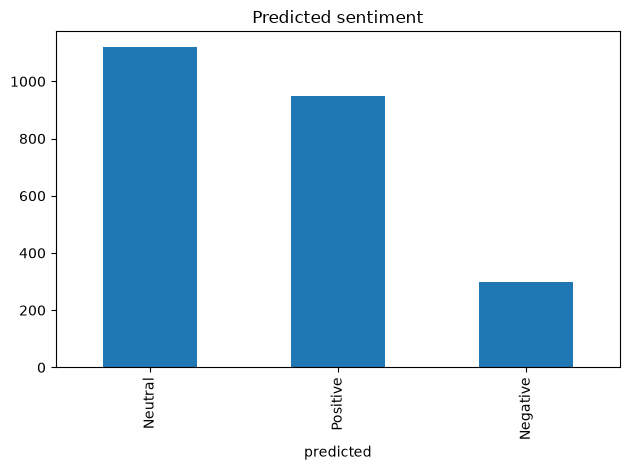

In [7]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

# Small editable Tagalog+English lexicon (word -> -2..+2). Extend with words YOUR data uses.
LEXICON = {
    'mabuhay':1.5,'salamat':1.2,'love':1.5,'proud':1.3,'suporta':1.2,'solid':1.2,'husay':1.2,
    'ganda':1.0,'saya':1.2,'galing':1.2,'totoo':0.8,'tama':0.8,'katotohanan':0.8,'laban':0.8,
    'corrupt':-1.8,'kurakot':-1.8,'sinungaling':-1.7,'magnanakaw':-1.8,'anomalya':-1.4,
    'galit':-1.4,'nakakagalit':-1.5,'nakakadismaya':-1.4,'dismaya':-1.2,'nakakahiya':-1.3,
    'fake':-1.0,'gulo':-0.8,'drama':-0.8,'tutol':-1.0,'managot':-0.8,'impeach':-0.7,'impeachment':-0.5,
    # holdout-driven negatives: 19/24 gold Neg missed with lex_hits==0 (tone, not stance).
    # NOT added on purpose: prayer/god/bless, good/job (sarcasm traps), law alone (neutral).
    'sayang':-1.2,'kapal':-1.3,'bugok':-1.5,'hiya':-1.2,'sinisira':-1.3,'sira':-1.2,
    'bend':-0.8,'bending':-0.9,'hate':-1.4,'nakakainis':-1.4,'nakakagigil':-1.4,
    'demonyo':-1.5,'basura':-1.3,'trapo':-1.2,'trapos':-1.2,'budol':-1.3,'ulol':-1.4,'hayop':-1.4,
}

NEG = {'hindi','huwag','wag','wala','walang','never','not','no','none','ni','di','ayaw'}
INTEN = {'sobra':1.5,'sobrang':1.5,'masyado':1.5,'grabe':1.5,'napaka':1.6,'very':1.5,'super':1.5,'talaga':1.3}

def rule_score(text, toks):
    v = vader.polarity_scores(str(text))['compound']  # -1..+1
    hits, vals = 0, []
    for i, w in enumerate(toks):
        if w in LEXICON:
            s = LEXICON[w]
            window = toks[max(0,i-3):i]
            if any(x in NEG for x in window): s = -s       # hindi maganda -> negative
            if any(x in INTEN for x in window): s *= 1.5   # sobrang galit counts extra
            vals.append(s); hits += 1
    lex = float(np.mean(vals)) if vals else 0.0
    return 0.4*(v*2)/2 + 0.6*lex/2, v, (sum(vals) if vals else 0.0), hits  # final in ~[-1,+1]

out = df.apply(lambda r: rule_score(r['text'], r['tokens']), axis=1, result_type='expand')
df['final_score'], df['vader'], df['lex_sum'], df['lex_hits'] = out[0], out[1], out[2], out[3]
df['predicted'] = np.where(df['final_score'] >= POS_THRESH, 'Positive', np.where(df['final_score'] <= NEG_THRESH, 'Negative', 'Neutral'))

dist = df['predicted'].value_counts()
net = dist.get('Positive',0)/len(df)*100 - dist.get('Negative',0)/len(df)*100
print(dist)
print(f'net sentiment = {net:+.1f} (pos% - neg%) · zero-lexicon-hits = {(df["lex_hits"]==0).mean():.0%}')
print('\nNET BY PLATFORM:')
print(df.groupby('platform')['predicted'].apply(lambda s: pd.Series({
    'n': len(s), 'pos%': (s=='Positive').mean()*100, 'neg%': (s=='Negative').mean()*100, 'net': (s=='Positive').mean()*100-(s=='Negative').mean()*100})).round(1))
df['predicted'].value_counts().plot.bar(title='Predicted sentiment'); plt.tight_layout(); plt.show()


## §7 Validation — 90/10 holdout + 10-fold CV (no leakage)

**Protocol (do in order):** 1) stratified 90/10 split (`seed=42`) BEFORE any tuning → 2) 10-fold stratified CV on the 90% dev set (tune lexicon/thresholds here only) → 3) final one-time eval on locked 10%. Re-splitting after peeking = leakage.

**Metrics:** accuracy, macro/weighted-F1, per-class precision/recall/F1, confusion matrix. CV reports mean±SD (SD>0.05 = unstable); CV−holdout>0.10 = overfit flag.

**Labels needed:** validation runs on `manual_sentiment` only. Aim 200+ stratified labels (mix platforms). Current file has few — the cell adapts folds automatically and tells you how many more to label.

In [8]:
LABELS = ['Positive','Negative','Neutral']
lab = df[df['manual_sentiment'].isin(LABELS)].copy()
print(f'labeled rows: {len(lab)} (need 200+ for report; minimum 15 to run)')
if len(lab): print(lab['manual_sentiment'].value_counts())

if len(lab) < 15 or lab['manual_sentiment'].value_counts().min() < 2:
    print('\n⏳ NOT ENOUGH LABELS — unsupervised results above are final; validation unlocks after labeling.')
    print('How to label: open data/raw_data.csv, fill manual_sentiment per row (Positive/Negative/Neutral = TONE of wording),')
    print('save as data/gold_labels.csv with columns id,manual_sentiment,political_bloc, then re-run this cell.')
    print('Tip: label a stratified sample (~70 Facebook / 70 YouTube / 60 X) to fix the FB-heavy bias.')
else:
    dev, hold = train_test_split(lab, test_size=HOLDOUT_FRAC, random_state=RANDOM_STATE, stratify=lab['manual_sentiment'])
    print(f'\nlocked split: dev={len(dev)} holdout={len(hold)} (seed {RANDOM_STATE}) — do NOT re-split after tuning')
    # classify_fn replays the CURRENT rule on any frame (tune LEXICON/thresholds, re-run CV here)
    def classify_fn(frame):
        return frame.apply(lambda r: rule_score(r['text'], r['tokens'])[0], axis=1).apply(
            lambda s: 'Positive' if s >= POS_THRESH else ('Negative' if s <= NEG_THRESH else 'Neutral')).tolist()
    dev = dev.copy(); dev['pred_dev'] = classify_fn(dev)  # predictions on dev for CV baseline
    min_cls = int(dev['manual_sentiment'].value_counts().min())
    folds = max(2, min(CV_FOLDS, min_cls))
    if folds < CV_FOLDS:
        print(f'⚠️ only {min_cls}/class in dev → using {folds}-fold CV (report as limitation; label more to reach 10-fold)')
    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
    accs, f1s = [], []
    from sklearn.metrics import f1_score
    for tr, te in skf.split(dev, dev['manual_sentiment']):
        yt = dev['manual_sentiment'].iloc[te].tolist()
        yp = [dev['pred_dev'].iloc[i] for i in te]  # rule is fixed: same function each fold
        accs.append(accuracy_score(yt, yp)); f1s.append(f1_score(yt, yp, average='macro', zero_division=0))
    print(f'CV (dev): acc {np.mean(accs):.3f}±{np.std(accs):.3f} · macro-F1 {np.mean(f1s):.3f}±{np.std(f1s):.3f}' + (' ⚠️ UNSTABLE (SD>0.05)' if np.std(f1s) > 0.05 else ' ✓ stable'))
    # final one-time eval on locked holdout
    hold = hold.copy(); hold['predicted_hold'] = classify_fn(hold)
    yh, yhp = hold['manual_sentiment'].tolist(), hold['predicted_hold'].tolist()
    print(f'\nHOLDOUT: acc={accuracy_score(yh, yhp):.3f}')
    print(classification_report(yh, yhp, digits=3, zero_division=0))
    print('confusion matrix (rows=gold, cols=pred [Positive,Negative,Neutral]):')
    print(confusion_matrix(yh, yhp, labels=LABELS))
    gap = float(np.mean(f1s)) - f1_score(yh, yhp, average='macro', zero_division=0)
    print(f'overfit check CV-holdout gap={gap:+.3f}' + (' ⚠️ possible overfit (>0.10)' if gap > 0.10 else ' ✓ ok'))
    err = hold[hold['manual_sentiment'] != hold['predicted_hold']][['text','manual_sentiment','predicted_hold','political_bloc']].head(10)
    print(f'\nerrors: {len(hold[hold["manual_sentiment"]!=hold["predicted_hold"]])}/{len(hold)} — read each row (tone≠stance, sarcasm, negation?):')
    print(err.to_string() if len(err) else '(no errors — verify holdout is not trivially small)')

labeled rows: 37 (need 200+ for report; minimum 15 to run)
manual_sentiment
Negative    24
Positive     9
Neutral      4
Name: count, dtype: int64

locked split: dev=33 holdout=4 (seed 42) — do NOT re-split after tuning
⚠️ only 4/class in dev → using 4-fold CV (report as limitation; label more to reach 10-fold)
CV (dev): acc 0.215±0.107 · macro-F1 0.149±0.046 ✓ stable

HOLDOUT: acc=0.000
              precision    recall  f1-score   support

    Negative      0.000     0.000     0.000       3.0
     Neutral      0.000     0.000     0.000       0.0
    Positive      0.000     0.000     0.000       1.0

    accuracy                          0.000       4.0
   macro avg      0.000     0.000     0.000       4.0
weighted avg      0.000     0.000     0.000       4.0

confusion matrix (rows=gold, cols=pred [Positive,Negative,Neutral]):
[[0 0 1]
 [1 0 2]
 [0 0 0]]
overfit check CV-holdout gap=+0.149 ⚠️ possible overfit (>0.10)

errors: 4/4 — read each row (tone≠stance, sarcasm, negation?):
   

## §8 Report table (Main_obj Section E) + conclusion

Copy this table into the report; each row = script → output → remark. Numbers come from the cells above (re-run to refresh).

| # | Script (this notebook) | Output (your data) | Remark |
|---|---|---|
| 1 | §1 Load + dedup | rows, platform counts, labeled count | FB-heavy sample = limitation; webscraped starts unlabeled |
| 2 | §2 Clean | kept/total %, top-25 words | top words should be content words; else add stopwords |
| 3 | §4 k-search 3..6 | coherence + perplexity per k, best-k | best-k = max coherence; perplexity is fit-only |
| 4 | §5 Topics | top-10 words, 2 examples/topic, share/platform | human names topics; merge k if two topics identical |
| 5 | §6 Rule-based sentiment | distribution, net overall + per platform, zero-hit % | zero-hit % = lexicon weakness; report thresholds |
| 6 | §7 Validation | CV mean±SD, holdout acc/macro-F1, per-class P/R/F1, confusion matrix, errors | tune on dev only; holdout evaluated once |

**Conclusion template:** state best-k + what each named topic means, net sentiment per platform, holdout macro-F1 with weak classes, and 3 limitations (FB bias, lexicon coverage, small labels). **References:** scikit-learn LDA/CV docs, VADER (Hutto & Gilbert 2014), NLTK stopwords, stopwords-iso (Tagalog list). **AI disclosure:** record tool + % + use (e.g. code drafting), per Main_obj H.

In [9]:
# Save key tables for the report appendix (one click)
os.makedirs('outputs_simple', exist_ok=True)
df[['id','platform','text','clean_text','topic','predicted','manual_sentiment','political_bloc']].to_csv('outputs_simple/clean_dataset.csv', index=False)
k_table.to_csv('outputs_simple/topic_k_search.csv', index=False)
tw_df.to_csv('outputs_simple/topic_top_words.csv', index=False)
share.to_csv('outputs_simple/topic_share_per_platform.csv')
print('saved to outputs_simple/ (4 CSVs) · attach in appendix + link repo')

saved to outputs_simple/ (4 CSVs) · attach in appendix + link repo
